# Stage 3 — Source-Grounded RAG for AI Governance

This notebook builds and evaluates question answering over the AI Media Dataset, using the AI Governance track and the source-linked Stage 1 graph handoff. It compares **text-only RAG**, **graph-aware RAG**, and **graph-aware RAG with cross-encoder re-ranking**.

The workflow follows the course [RAG skeleton](https://github.com/umagira/anatoolbox/blob/main/notebooks/course_project_skeleton.ipynb): source preparation, retrieval evaluation, answer generation, graph integration and one evaluated enhancement. The components are implemented directly in `src/stage3_rag/` to preserve our Stage 1 identifiers, exact offsets and local-model caches.

**Evaluation status:** Q&A drafts and the secondary source audit are explicitly AI-assisted. The assignment's genuine manual Q&A review remains a separate recorded step. Until that review is complete, evaluation results are provisional rather than a human-validated benchmark.


## 1. Design and execution settings

| Component | Choice |
|---|---|
| Source period | 1 September 2024–31 August 2026; publication dates preserved |
| Benchmark evidence | 120 passages from positively source-reviewed, originally tagged Governance articles |
| Q&A generation | 240 source-grounded pairs authored with ChatGPT / Codex, different from the RAG model |
| Sparse retrieval | TF-IDF unigrams/bigrams, capped at 120,000 features |
| Dense retrieval | Cached `sentence-transformers/all-MiniLM-L6-v2`; exact input-coverage audit |
| Hybrid retrieval | Reciprocal-rank fusion of sparse and dense ranking |
| Graph augmentation | Typed entity anchors, bounded source-backed expansion, reviewed semantic facts |
| Answer model | Existing local Ollama `llama3.2:latest` |
| Enhancement | Cached `cross-encoder/ms-marco-MiniLM-L6-v2` re-ranks the same candidate pool |
| Answer evaluation | The same 60 preselected test questions across all three systems |
| AI judgment | Local `mistral:latest`, on the same 15 preselected questions per system |

The development set chooses the text retriever and motivates the enhancement; test data reports the final comparison. The full test set measures retrieval. The smaller fixed answer/judge subsets bound local inference cost and cover all five question categories. Their IDs are frozen before generating answers.

The default settings display existing computed results. Enable the run switches to recompute experiments; matching fingerprints reuse caches. RAG answering and AI judging use the local Ollama endpoint. The separately authored Q&A drafts were created with ChatGPT / Codex in this coding session. Stage 2's QLoRA models are theme classifiers, so this notebook uses a generative local model for answering.


In [1]:
from pathlib import Path
import json
import os
import sys
import platform

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "notebooks/stage1_ai_governance/Stage1_AI_Governance.ipynb").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.stage3_rag.common import fingerprint, read_jsonl, sha256_file, write_json
from src.stage3_rag.data import prepare_qa_dataset
from src.stage3_rag.pipeline import prepare_data, build_index, run_retrieval_experiments, run_answer_experiments
from src.stage3_rag.snapshot import preflight_answers
from src.stage3_rag.generation import OllamaGenerator

SEED = 42
RUN_RETRIEVAL = False
RUN_ANSWER_GENERATION = False
RUN_AI_JUDGE = False
RUN_LIVE_QUERY = False
RESULTS_DIR = PROJECT_ROOT / "outputs/results/stage3"
FIGURES_DIR = PROJECT_ROOT / "outputs/figures/stage3"
DATA_DIR = PROJECT_ROOT / "data/processed/stage3"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)

print("Python:", sys.version.split()[0], "| machine:", platform.machine(), "| CPU threads:", torch.get_num_threads())
print("Generator: local llama3.2 | Q&A author: ChatGPT / Codex | AI judge: local Mistral")

from importlib.metadata import version
environment = {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "torch", "transformers", "sentence-transformers", "networkx"]}
environment.update(python=sys.version.split()[0], machine=platform.machine(), cpu_threads=torch.get_num_threads())
write_json(RESULTS_DIR / "environment.json", environment)
display(pd.Series(environment, name="Version/runtime").to_frame())


Python: 3.12.4 | machine: arm64 | CPU threads: 4
Generator: local llama3.2 | Q&A author: ChatGPT / Codex | AI judge: local Mistral


,Version/runtime
numpy,2.2.6
pandas,3.1.0
scipy,1.17.1
scikit-learn,1.8.0
torch,2.10.0
transformers,4.57.6
sentence-transformers,5.2.3
networkx,3.6.1
python,3.12.4
machine,arm64


## 2. Corpus, chunks and Stage 1 provenance

The retrieval collection reuses the original tagged Governance sources after the Stage 1 date restriction and explicit negative reviews. Recorded uncertain articles are excluded here. Remaining unreviewed articles retain their weak-label status; this is not a new corpus-wide relevance classifier.

Chunk boundaries use the actual fast tokenizer's original-text offsets: **200 body wordpieces, 32-wordpiece overlap**, and at most 32 title wordpieces for dense indexing. Dense inputs are checked against MiniLM's 256-wordpiece limit; full-article encoding is not claimed. Publication dates are supplied separately to the answer model.

Every chunk has a stable ID, `record_id`, original `char_start`/`char_end`, article fingerprint, publication date and review provenance. Benchmark passages are selected from these same chunks before drafting questions. A passage-level source check replaced a few generic/footer excerpts with concrete Governance sections; original article membership and split were preserved.


In [2]:
chunks, passages, graph, entity_articles, chunk_manifest = prepare_data(PROJECT_ROOT)
index = build_index(PROJECT_ROOT, chunks)
index_summary = json.loads((RESULTS_DIR / "index_summary.json").read_text())
display(pd.DataFrame({"Metric": ["Retrieval articles", "Retrieval chunks", "Selected passages", "Benchmark source articles", "Maximum dense input tokens", "Truncated dense inputs"],
                      "Value": [chunk_manifest["source_articles"], len(chunks), len(passages), passages.record_id.nunique(),
                                index.coverage_report["input_tokens_max"], index.coverage_report["embedding_truncated_chunks"]]}))
assert index.coverage_report["embedding_truncated_chunks"] == 0
assert index.coverage_report["tokenizer_verified"]
display(passages[["passage_id", "record_id", "date", "title", "split"]].head(8))
print("Index cache hit:", index.index_cache_hit)
print("Original index-build seconds:", index_summary.get("initial_index_build_seconds"))


Building/loading sparse and dense indices for 188,873 chunks...
Index cache hit: True
Original index-build seconds: 2013.7767086250242


,Metric,Value
0,Retrieval articles,12805
1,Retrieval chunks,188873
2,Selected passages,120
3,Benchmark source articles,66
4,Maximum dense input tokens,238
5,Truncated dense inputs,0


,passage_id,record_id,date,title,split
0,0492f26018960b4cfeb858fb,144536,2024-09-18,Why We Must Approach AI Like the Automobile,development
1,890134dd1144c135fb4e5861,144536,2024-09-18,Why We Must Approach AI Like the Automobile,development
2,973f2ee3837fde80e13ef64f,144536,2024-09-18,Why We Must Approach AI Like the Automobile,development
3,82d7f1d765e4ad829ecf08da,151969,2025-05-12,AI can guess racial categories from heart scan...,development
4,ba0e9ec6df820cf84b5ae775,169583,2025-06-06,microsoft/NatureLM-8x7B-Inst · Hugging Face,development
5,7e1727e31ce7b03a808aea3a,110621,2025-08-05,Generative AI – Changing the game with KymChat,development
6,9045857d5c9a74563b5e8694,110621,2025-08-05,Generative AI – Changing the game with KymChat,development
7,5ceaf99ce100cb8858921f54,46965,2025-08-06,"Trump’s AI Action Plan, Explained",development


## 3. Q&A dataset: draft, source check and manual review

The 120 passages cover multiple Governance dimensions, entities, sources and time periods. Each supplies two distinct questions. Categories are factual, temporal, relational, analytical and comparative; comparative/analytical answers must remain supported by that passage, without external facts.

ChatGPT / Codex authored the 240 pairs from the actual passages. A separate AI-assisted source audit checked 30 questions across categories and both splits; it removed one unsupported “first” presupposition. Exact evidence spans and article identities are checked programmatically for every pair. These checks do not substitute for the manual review required by the assignment.

Use `qa_manual_review.csv` and `qa_review_packet.html` to check clarity, correctness, diversity, coverage and source answerability. Genuine human reviewers record `approved`, `rejected` or `needs_revision`, their identity/date, and optional corrected question, answer and evidence. Existing edits survive reruns. Changed reviewed drafts stop execution instead of silently inheriting approval. Evaluation uses approved corrections when available, while pending draft results remain explicitly provisional.


In [3]:
qas, qa_review, qa_manifest = prepare_qa_dataset(PROJECT_ROOT, passages)
display(pd.crosstab(qas["category"], qas["split"]).reindex(["factual", "temporal", "relational", "analytical", "comparative"]))
display(qas[["qa_id", "category", "question", "reference_answer", "gold_evidence"]].head(5))
print("Manual Q&A review:", DATA_DIR / "qa_manual_review.csv")
print("Reading packet:", RESULTS_DIR / "qa_review_packet.html")
print("Human approved:", qa_manifest["human_approved"], "/", qa_manifest["draft_questions"])
print("Evaluation label status:", qa_manifest["evaluation_status"])
assert qas.groupby("record_id")["split"].nunique().max() == 1
assert qas.qa_id.is_unique


Manual Q&A review: /Users/henrik/Documents/CTL/data/processed/stage3/qa_manual_review.csv
Reading packet: /Users/henrik/Documents/CTL/outputs/results/stage3/qa_review_packet.html
Human approved: 0 / 240
Evaluation label status: provisional_on_ai_drafts


split,development,test
category,,
factual,11,45
temporal,7,26
relational,11,36
analytical,18,37
comparative,15,34


,qa_id,category,question,reference_answer,gold_evidence
0,q_0492f26018960b4cfeb858fb_1,factual,Which three ethical priorities does the articl...,"It calls for fairness, transparency, and accou...","We must also ensure AI development is ethical,..."
1,q_0492f26018960b4cfeb858fb_2,comparative,How do the proposed AI benefits differ between...,Education would adapt learning to individual n...,Personalized education powered by AI can adapt...
2,q_890134dd1144c135fb4e5861_1,analytical,Why does the author advocate digital inclusion...,They would provide tools and resources to part...,This requires advocating for digital inclusion...
3,q_890134dd1144c135fb4e5861_2,relational,Which groups should jointly create the AI regu...,"Governments, businesses, and civil society sho...","Governments, businesses, and civil society mus..."
4,q_973f2ee3837fde80e13ef64f_1,factual,Which governance standards does the article ca...,"It calls for standards for data privacy, AI tr...","This means setting standards for data privacy,..."


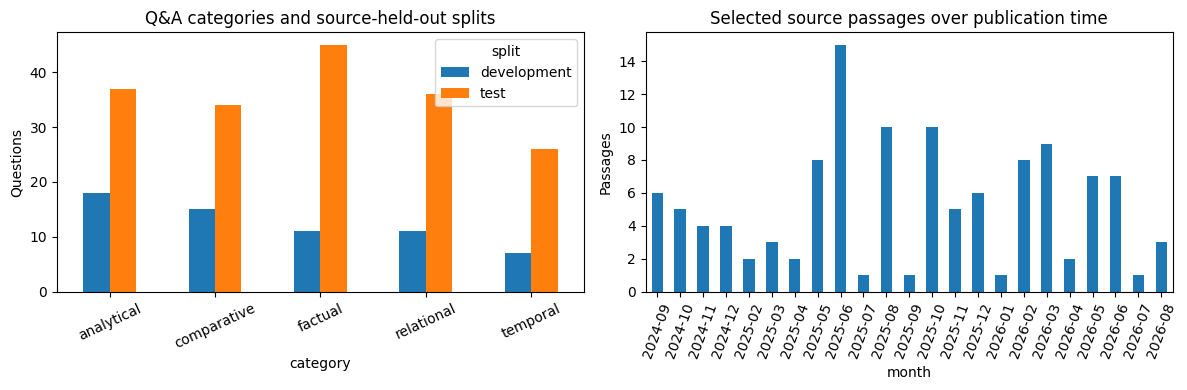

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(qas["category"], qas["split"]).plot.bar(ax=axes[0], rot=25)
axes[0].set_title("Q&A categories and source-held-out splits")
axes[0].set_ylabel("Questions")
passages.assign(month=pd.to_datetime(passages.date).dt.to_period("M").astype(str)).groupby("month").size().plot.bar(ax=axes[1], rot=70)
axes[1].set_title("Selected source passages over publication time")
axes[1].set_ylabel("Passages")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "dataset_coverage.png", dpi=140, bbox_inches="tight")
plt.show()


## 4. Retrieval baselines and development-only selection

Sparse retrieval preserves precise law, regulator and product names. Dense retrieval handles semantic paraphrases. Hybrid retrieval fuses ranks without assuming comparable raw score scales. The text retriever is chosen by **development MRR@4**, then Recall@4 and a deterministic tie-break.

The index contains the document collection, including evidence for test questions, as a retrieval collection should. It never indexes Q&A questions, reference answers or gold labels. Article-level splitting prevents questions derived from the same article from entering both development and test. Sparse indexing uses passage bodies; dense indexing adds the bounded title prefix described above. These are practical retrieval configurations, not an isolated comparison of embedding architectures.

Primary metrics recover the authored evidence chunk: Recall@4, MRR@4 and nDCG@4. Article-source hit rate is reported separately. Gold chunks are not exhaustive relevance judgments: an overlapping or alternative chunk can answer correctly without matching the exact authored ID.


In [5]:
if RUN_RETRIEVAL:
    run_retrieval_experiments(PROJECT_ROOT, index, qas, graph, entity_articles)
if not (RESULTS_DIR / "retrieval_manifest.json").exists():
    raise RuntimeError("Run the retrieval experiment first: python -m src.stage3_rag.pipeline --retrieval")
retrieval_manifest = json.loads((RESULTS_DIR / "retrieval_manifest.json").read_text())
if retrieval_manifest["qa_fingerprint"] != fingerprint(qas.to_dict("records")):
    raise RuntimeError("Q&A snapshot changed. Rerun retrieval before displaying or generating evaluation results.")
selection = pd.read_csv(RESULTS_DIR / "development_retriever_comparison.csv")
display(selection.loc[selection.category.eq("all"), ["variant", "n_questions", "recall_at_k", "mrr", "ndcg_at_k", "gold_record_retrieved"]])
print("Validation-selected text retriever:", retrieval_manifest["selected_text_mode"])


Validation-selected text retriever: hybrid


,variant,n_questions,recall_at_k,mrr,ndcg_at_k,gold_record_retrieved
0,dense,62,0.209677,0.174731,0.183755,0.290323
6,hybrid,62,0.387097,0.271505,0.300757,0.483871
12,sparse,62,0.354839,0.254032,0.279793,0.451613


## 5. Graph-aware retrieval and source-bound semantic facts

The Stage 1 handoff supplies typed canonical entity IDs and dated entity/article membership. Query entities anchor a bounded graph expansion; candidate passages are ranked against the original query. High graph degree alone does not establish relevance.

The two evidence meanings remain distinct:

- Co-occurrence edges guide retrieval expansion. Tag-derived theme associations remain descriptive metadata. Neither establishes a directional relationship.
- Reviewed semantic edges retain subject, predicate, object, exact quote, source article/date and review method. Rare relation-only entities can resolve through edge-level source provenance even when absent from the frequency-filtered NER graph.

Only supported semantic facts whose exact quote occurs inside an actual retrieved, capped passage may enter the answer prompt. They reuse that passage's citation ID. Associations, stale source bindings, mismatched dates and quotes outside the excerpt are excluded from factual prompts. The graph is source-linked; its reviews remain AI-assisted.


Reviewed semantic source assertions available: 22
NER entity/article memberships available: 138690
Graph storage: 855 nodes / 14226 directed storage edges


,subject,relation,object,record_id,date,evidence,review_method
0,ORG::Google,DEVELOPS,MODEL::Gemma,44425,2025-05-09,"Gemma is a family of lightweight, state-of-the...",ai_assisted
1,ORG::Google,DEVELOPS,PRODUCT::Opal,171766,2025-10-08,Google has expanded the release of its vibe-co...,ai_assisted
2,ORG::Google,DEVELOPS,STANDARD::Secure AI Framework,69083,2026-01-17,"At Google, we know that security and data priv...",ai_assisted
3,ORG::Google,DEVELOPS,PRODUCT::Gemini CLI,51569,2026-06-10,Google built Gemini CLI with a terminal-first ...,ai_assisted
4,ORG::OpenAI,DEVELOPS,MODEL::GPT,74687,2024-11-08,"OpenAI released its first GPT model in 2018, a...",ai_assisted
5,ORG::Microsoft,COMPLIES_WITH,STANDARD::Responsible AI Standard,104296,2025-08-21,Microsoft embeds Responsible AI principles int...,ai_assisted
6,ORG::European Union,ADOPTS,LAW::EU AI Act,67189,2026-05-07,"The AI Act, adopted in 2024, is the EU’s centr...",ai_assisted
7,LAW::EU AI Act,REGULATES,TECHNOLOGY::Artificial Intelligence,172313,2024-09-26,The EU AI Act uses a risk-based classification...,ai_assisted


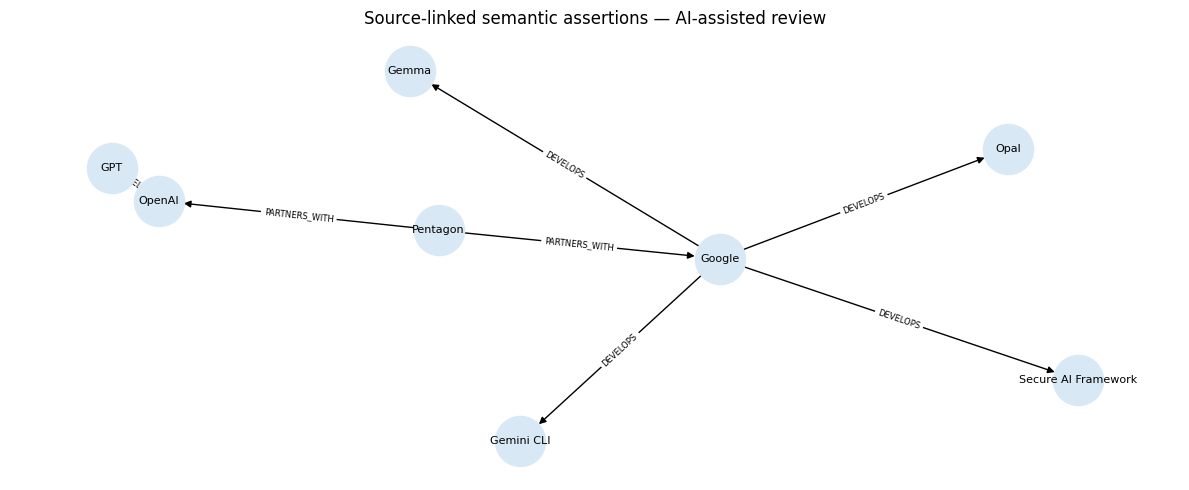

In [6]:
semantic_edges = []
for source, target, attrs in graph.edges(data=True):
    if attrs.get("fact_assertion") is True:
        semantic_edges.append({"subject": source, "relation": attrs["relation"], "object": target,
                               "record_id": attrs["record_id"], "date": attrs["date"],
                               "evidence": attrs["evidence"], "review_method": attrs["review_method"]})
display(pd.DataFrame(semantic_edges).head(8))
print("Reviewed semantic source assertions available:", len(semantic_edges))
print("NER entity/article memberships available:", len(entity_articles))
print("Graph storage:", graph.number_of_nodes(), "nodes /", graph.number_of_edges(), "directed storage edges")

# A compact view of the reviewed semantic layer; associations are separate.
semantic_view = nx.DiGraph()
for row in semantic_edges:
    semantic_view.add_edge(row["subject"], row["object"], relation=row["relation"])
if semantic_view.number_of_edges():
    component = max(nx.weakly_connected_components(semantic_view), key=len)
    nodes = sorted(component, key=lambda node: (-semantic_view.degree(node), node))[:12]
    view = semantic_view.subgraph(nodes)
    positions = nx.spring_layout(view, seed=SEED)
    fig, ax = plt.subplots(figsize=(12, 5))
    nx.draw_networkx(view, positions, ax=ax, labels={node:node.split("::", 1)[-1] for node in view},
                     node_size=1300, node_color="#d9e8f5", font_size=8, arrows=True)
    nx.draw_networkx_edge_labels(view, positions, ax=ax, edge_labels=nx.get_edge_attributes(view, "relation"), font_size=6)
    ax.set_title("Source-linked semantic assertions — AI-assisted review")
    ax.axis("off")
    fig.tight_layout(); fig.savefig(FIGURES_DIR / "semantic_graph_example.png", dpi=140, bbox_inches="tight")
    plt.show()


## 6. One evaluated enhancement: cross-encoder re-ranking

The development analysis measures whether authored evidence appears in the top 20 candidates but misses the four-passage answer context. That gap motivates re-ranking, which can promote relevant candidates already present; it cannot recover evidence outside the candidate pool.

The graph and graph-plus-reranker variants use the same candidate-construction rules and the same 20-candidate cap. The latter applies the cached cross encoder before retaining four passages. The enhancement is evaluated rather than assumed beneficial. Its choice and configuration are fixed before inspecting the test comparison.


,Metric,Value
0,Development Recall@4,0.387097
1,Development candidate Recall@20,0.645161
2,Candidate-to-context recall gap,0.258065


,variant,n_questions,recall_at_k,mrr,ndcg_at_k,gold_record_retrieved
0,graph,178,0.556180,0.448034,0.475158,0.646067
6,graph_rerank,178,0.741573,0.682584,0.697588,0.797753
12,text_only,178,0.573034,0.460674,0.488990,0.657303


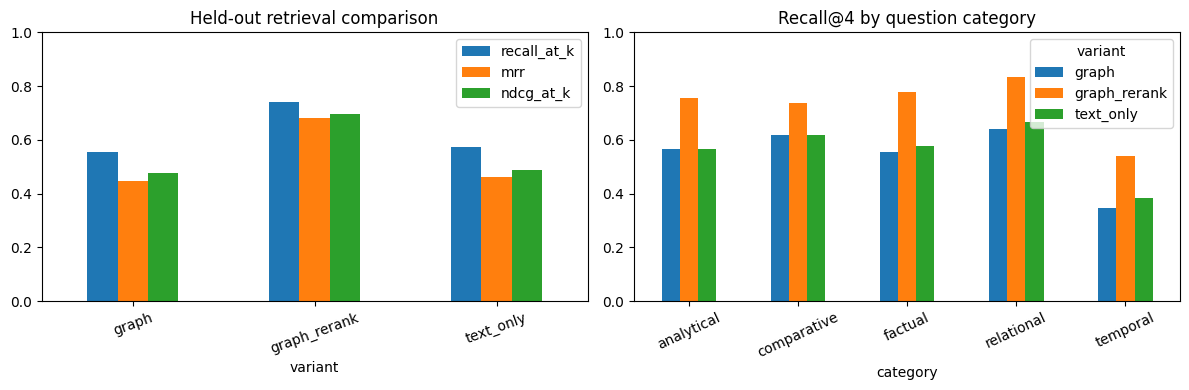

In [7]:
enhancement = json.loads((RESULTS_DIR / "enhancement_design.json").read_text())
display(pd.DataFrame({"Metric": ["Development Recall@4", "Development candidate Recall@20", "Candidate-to-context recall gap"],
                      "Value": [enhancement["development_recall_at_4"], enhancement["development_candidate_recall_at_20"], enhancement["candidate_context_recall_gap"]]}))
retrieval_results = pd.read_csv(RESULTS_DIR / "test_retrieval_summary.csv")
display(retrieval_results.loc[retrieval_results.category.eq("all"), ["variant", "n_questions", "recall_at_k", "mrr", "ndcg_at_k", "gold_record_retrieved"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
retrieval_results.loc[retrieval_results.category.eq("all")].set_index("variant")[["recall_at_k", "mrr", "ndcg_at_k"]].plot.bar(ax=axes[0], rot=20, ylim=(0, 1))
axes[0].set_title("Held-out retrieval comparison")
retrieval_results.loc[retrieval_results.category.ne("all")].pivot(index="category", columns="variant", values="recall_at_k").plot.bar(ax=axes[1], rot=25, ylim=(0, 1))
axes[1].set_title("Recall@4 by question category")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "retrieval_comparison.png", dpi=140, bbox_inches="tight")
plt.show()


## 7. Local answer generation

All systems use the same Ollama Llama 3.2 model, fixed seed/temperature, four-passage context budget and structured output schema. Sources carry publication dates. The prompt requires answers from retrieved evidence, numbered citations, and an explicit insufficiency response when context is inadequate. The structured output permits a supporting quote or null; any supplied quote must match a cited passage exactly.

At most five source-bound graph facts fit inside the same serialized source-envelope cap of 12,000 characters. Prompt tokens and generation times are recorded; graph metadata can increase prompt length, so runtime differences are practical system costs rather than an isolated architectural speed comparison.

Invalid JSON, schema, citations or quotations remain explicit failures. No reference answer is inserted into the generation prompt, and no extractive answer is substituted for a failed LLM output. Raw local responses, token counts, model digests and configuration are cached with their exact inputs.


In [8]:
answer_sample, test_runs, checked_qa_manifest = preflight_answers(PROJECT_ROOT)
if RUN_ANSWER_GENERATION:
    run_answer_experiments(PROJECT_ROOT, run_judge=RUN_AI_JUDGE)
if not (RESULTS_DIR / "answer_runs.json").exists():
    raise RuntimeError("Run local answers first: python -m src.stage3_rag.pipeline --answers --judge")
answer_runs = json.loads((RESULTS_DIR / "answer_runs.json").read_text())
answer_manifest = json.loads((RESULTS_DIR / "answer_manifest.json").read_text())
for key, path in {
    "answer_sample_sha256": DATA_DIR / "answer_evaluation_sample.jsonl",
    "retrieval_runs_sha256": RESULTS_DIR / "test_retrieval_runs.json",
    "answer_runs_sha256": RESULTS_DIR / "answer_runs.json",
    "answer_per_question_sha256": RESULTS_DIR / "answer_per_question.csv",
    "answer_summary_sha256": RESULTS_DIR / "answer_summary.csv",
}.items():
    if answer_manifest.get(key) != sha256_file(path):
        raise RuntimeError("Answer snapshot changed. Rerun local answers before displaying the comparison.")
if answer_manifest["qa_label_status"] != checked_qa_manifest["evaluation_status"]:
    raise RuntimeError("Answer label status differs from the current Q&A review snapshot.")
assert answer_manifest["generation_code_sha256"] == sha256_file(PROJECT_ROOT / "src/stage3_rag/generation.py")
assert answer_manifest["evaluation_code_sha256"] == sha256_file(PROJECT_ROOT / "src/stage3_rag/evaluation.py")
display(answer_sample.groupby("category").size().rename("Paired answer questions").to_frame())
print("Answer model identity:", answer_manifest["generator"])
print("Question author:", answer_manifest["qa_generator"])
print("Different question-generation and answer models:", answer_manifest["different_qa_and_answer_models"])


Answer model identity: {'requested_model': 'llama3.2:latest', 'digest': 'a80c4f17acd55265feec403c7aef86be0c25983ab279d83f3bcd3abbcb5b8b72', 'name': 'llama3.2:latest', 'details': {'parent_model': '', 'format': 'gguf', 'family': 'llama', 'families': ['llama'], 'parameter_size': '3.2B', 'quantization_level': 'Q4_K_M', 'context_length': 131072, 'embedding_length': 3072}}
Question author: ChatGPT / Codex
Different question-generation and answer models: True


,Paired answer questions
category,
analytical,12
comparative,12
factual,12
relational,12
temporal,12


## 8. System evaluation: proxies and executed source-only AI judgment

The 60 paired answer questions have 12 questions per category, sampled deterministically from held-out articles. The local Mistral judge assesses a further fixed paired subset of 15 questions (three per category). It sees only the actual question, generated answer, citations and actual capped source context, not the reference answer.

| Measurement | Meaning and limit |
|---|---|
| Reference token F1 | Lexical overlap with the draft reference; paraphrases can score poorly |
| Citation validity | Citations resolve to actual supplied passages |
| Exact quote grounding proxy | A quote occurs literally in a cited passage; this does not prove entailment |
| Gold context coverage | Authored evidence was visible to the generator |
| Temporal proxies | Reference-year recovery and publication-date mention, restricted to temporal questions |
| AI-judged faithfulness | Answer claims supported by supplied source text, score 1–5 |
| AI-judged relevance | Directness and adequacy for the query, score 1–5 |
| AI-judged context grounding | Appropriate use of source evidence/citations, score 1–5 |
| AI-judged temporal grounding | Supported dates/chronology for temporal questions, score 1–5 |

Generation success denotes passing JSON/schema/citation checks and literal validation of any supplied quote, not merely returning nonempty text. A null quote is permitted by the schema and scores zero on the exact-quote proxy for non-abstaining answers. A failed quotation check can accompany a substantively plausible answer. Absent or failed judge scores remain missing. Every aggregate reports its actual denominator; temporal judge scores therefore cover at most three questions per system. These are AI judgments, not human ratings. Small single-run differences do not establish statistical significance.


,variant,n_questions,generation_success,token_f1,citation_validity,gold_context_coverage,exact_quote_grounding_proxy,abstention_rate
0,graph,60,0.750000,0.253193,0.983333,0.466667,0.550000,0.0
6,graph_rerank,60,0.816667,0.328165,1.000000,0.616667,0.650000,0.0
12,text_only,60,0.700000,0.255546,0.983333,0.466667,0.516667,0.0


,variant,ai_judge_faithfulness,ai_judge_faithfulness_n,ai_judge_relevance,ai_judge_relevance_n,ai_judge_context_grounding,ai_judge_context_grounding_n,ai_judge_temporal_grounding,ai_judge_temporal_grounding_n
0,graph,3.666667,15,4.533333,15,4.133333,15,4.000000,3
6,graph_rerank,4.000000,15,4.666667,15,4.133333,15,4.666667,3
12,text_only,3.866667,15,4.733333,15,4.200000,15,3.333333,3


,variant,category,n_questions,token_f1,token_f1_n,citation_validity,citation_validity_n,exact_quote_grounding_proxy,exact_quote_grounding_proxy_n,ai_judge_faithfulness,ai_judge_faithfulness_n,ai_judge_relevance,ai_judge_relevance_n,ai_judge_context_grounding,ai_judge_context_grounding_n,ai_judge_temporal_grounding,ai_judge_temporal_grounding_n
1,graph,analytical,12,0.240970,12,1.000000,12,0.833333,12,4.333333,3,5.000000,3,4.333333,3,NaN,0
7,graph_rerank,analytical,12,0.276520,12,1.000000,12,0.916667,12,5.000000,3,5.000000,3,4.666667,3,NaN,0
13,text_only,analytical,12,0.238330,12,1.000000,12,0.833333,12,4.333333,3,5.000000,3,4.333333,3,NaN,0
2,graph,comparative,12,0.241380,12,1.000000,12,0.416667,12,3.333333,3,4.333333,3,3.666667,3,NaN,0
8,graph_rerank,comparative,12,0.319388,12,1.000000,12,0.666667,12,4.000000,3,4.666667,3,4.000000,3,NaN,0
14,text_only,comparative,12,0.241660,12,1.000000,12,0.416667,12,4.666667,3,5.000000,3,4.000000,3,NaN,0
3,graph,factual,12,0.229250,12,1.000000,12,0.416667,12,3.666667,3,4.666667,3,4.333333,3,NaN,0
9,graph_rerank,factual,12,0.326696,12,1.000000,12,0.833333,12,4.666667,3,5.000000,3,4.333333,3,NaN,0
15,text_only,factual,12,0.292607,12,1.000000,12,0.500000,12,3.666667,3,4.666667,3,4.666667,3,NaN,0
4,graph,relational,12,0.421773,12,1.000000,12,0.666667,12,3.333333,3,4.333333,3,4.333333,3,NaN,0


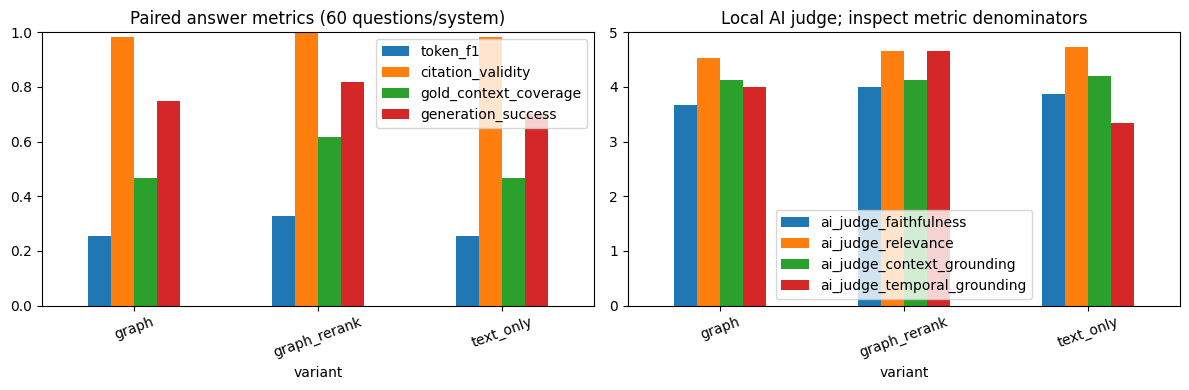

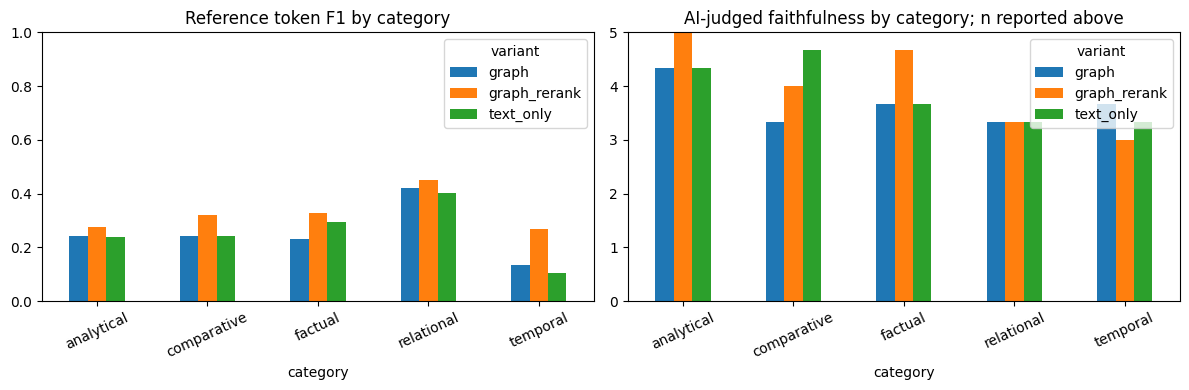

In [9]:
answer_results = pd.read_csv(RESULTS_DIR / "answer_summary.csv")
answer_rows = pd.read_csv(RESULTS_DIR / "answer_per_question.csv")
metrics = ["variant", "n_questions", "generation_success", "token_f1", "citation_validity", "gold_context_coverage", "exact_quote_grounding_proxy", "abstention_rate"]
display(answer_results.loc[answer_results.category.eq("all"), metrics])
judge_metrics = ["variant", "ai_judge_faithfulness", "ai_judge_faithfulness_n", "ai_judge_relevance", "ai_judge_relevance_n", "ai_judge_context_grounding", "ai_judge_context_grounding_n", "ai_judge_temporal_grounding", "ai_judge_temporal_grounding_n"]
display(answer_results.loc[answer_results.category.eq("all"), judge_metrics])
category_columns = ["variant", "category", "n_questions", "token_f1", "token_f1_n",
    "citation_validity", "citation_validity_n", "exact_quote_grounding_proxy", "exact_quote_grounding_proxy_n",
    "ai_judge_faithfulness", "ai_judge_faithfulness_n", "ai_judge_relevance", "ai_judge_relevance_n",
    "ai_judge_context_grounding", "ai_judge_context_grounding_n", "ai_judge_temporal_grounding", "ai_judge_temporal_grounding_n"]
display(answer_results.loc[answer_results.category.ne("all"), category_columns].sort_values(["category", "variant"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
answer_results.loc[answer_results.category.eq("all")].set_index("variant")[["token_f1", "citation_validity", "gold_context_coverage", "generation_success"]].plot.bar(ax=axes[0], rot=20, ylim=(0, 1))
axes[0].set_title("Paired answer metrics (60 questions/system)")
answer_results.loc[answer_results.category.eq("all")].set_index("variant")[["ai_judge_faithfulness", "ai_judge_relevance", "ai_judge_context_grounding", "ai_judge_temporal_grounding"]].plot.bar(ax=axes[1], rot=20, ylim=(0, 5))
axes[1].set_title("Local AI judge; inspect metric denominators")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "answer_comparison.png", dpi=140, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
category_results = answer_results.loc[answer_results.category.ne("all")]
category_results.pivot(index="category", columns="variant", values="token_f1").plot.bar(ax=axes[0], rot=25, ylim=(0, 1))
axes[0].set_title("Reference token F1 by category")
category_results.pivot(index="category", columns="variant", values="ai_judge_faithfulness").plot.bar(ax=axes[1], rot=25, ylim=(0, 5))
axes[1].set_title("AI-judged faithfulness by category; n reported above")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "answer_categories.png", dpi=140, bbox_inches="tight")
plt.show()


In [10]:
# Paired effects retain question identity and distinguish graph and reranking changes.
paired_effects = []
for label, before, after in [("Graph vs text", "text_only", "graph"), ("Re-ranking vs graph", "graph", "graph_rerank")]:
    for metric, frame in [("recall_at_k", pd.read_csv(RESULTS_DIR / "test_retrieval_per_question.csv")),
                          ("token_f1", answer_rows), ("ai_judge_faithfulness", answer_rows)]:
        pivot = frame.pivot(index="qa_id", columns="variant", values=metric)
        valid = pivot[[before, after]].dropna()
        paired_effects.append({"Comparison": label, "Metric": metric, "Paired questions": len(valid),
                               "Mean difference": (valid[after] - valid[before]).mean()})
display(pd.DataFrame(paired_effects))
print("Score differences are descriptive; no significance claim is made.")


Score differences are descriptive; no significance claim is made.


,Comparison,Metric,Paired questions,Mean difference
0,Graph vs text,recall_at_k,178,-0.016854
1,Graph vs text,token_f1,60,-0.002353
2,Graph vs text,ai_judge_faithfulness,15,-0.200000
3,Re-ranking vs graph,recall_at_k,178,0.185393
4,Re-ranking vs graph,token_f1,60,0.074972
5,Re-ranking vs graph,ai_judge_faithfulness,15,0.333333


In [11]:
# Interpret this run without selecting settings from the test results.
r_overall = retrieval_results.loc[retrieval_results.category.eq("all")].set_index("variant")
a_overall = answer_results.loc[answer_results.category.eq("all")].set_index("variant")
graph_recall_delta = r_overall.loc["graph", "recall_at_k"] - r_overall.loc["text_only", "recall_at_k"]
rerank_recall_delta = r_overall.loc["graph_rerank", "recall_at_k"] - r_overall.loc["graph", "recall_at_k"]
graph_f1_delta = a_overall.loc["graph", "token_f1"] - a_overall.loc["text_only", "token_f1"]
rerank_f1_delta = a_overall.loc["graph_rerank", "token_f1"] - a_overall.loc["graph", "token_f1"]
display(Markdown(
    f"**Observed contribution in this held-out run.** Graph expansion changes authored-evidence Recall@4 "
    f"by **{graph_recall_delta:+.1%}** compared with text-only retrieval; reference token F1 changes by "
    f"**{graph_f1_delta:+.3f}**. Re-ranking changes Recall@4 by **{rerank_recall_delta:+.1%}** relative to graph retrieval "
    f"and token F1 by **{rerank_f1_delta:+.3f}**. The sign of each measured change determines whether that component "
    f"helped this benchmark; graph connectivity alone is not evidence of improvement. "
    f"The development candidate-to-context recall gap was **{enhancement['candidate_context_recall_gap']:.1%}**, "
    f"which motivated testing the re-ranker before this final comparison."
))
display(Markdown(
    "**Implications for trend monitoring.** Dated source passages allow answers to distinguish reported proposals, "
    "historical developments and forecasts. Graph anchors can connect named actors and standards across sources, "
    "while reviewed triples remain limited by graph coverage. Re-ranking adds computation to select context more precisely. "
    "The category tables and local judge explanations show where these mechanisms help or fail; claims about corpus-wide "
    "trends, factual truth outside the articles or human-validated accuracy are not established by these provisional scores."
))


**Observed contribution in this held-out run.** Graph expansion changes authored-evidence Recall@4 by **-1.7%** compared with text-only retrieval; reference token F1 changes by **-0.002**. Re-ranking changes Recall@4 by **+18.5%** relative to graph retrieval and token F1 by **+0.075**. The sign of each measured change determines whether that component helped this benchmark; graph connectivity alone is not evidence of improvement. The development candidate-to-context recall gap was **25.8%**, which motivated testing the re-ranker before this final comparison.

**Implications for trend monitoring.** Dated source passages allow answers to distinguish reported proposals, historical developments and forecasts. Graph anchors can connect named actors and standards across sources, while reviewed triples remain limited by graph coverage. Re-ranking adds computation to select context more precisely. The category tables and local judge explanations show where these mechanisms help or fail; claims about corpus-wide trends, factual truth outside the articles or human-validated accuracy are not established by these provisional scores.

## 9. Inspect answers and limitations

The examples below are fixed by category/ID order, not chosen for high scores. Compare source dates, cited evidence, abstention and the actual answer. Exact quotations alone do not establish that the answer fully addresses the question.

The graph is incomplete and contains only a small reviewed semantic layer; associations remain much more numerous. The corpus filter still uses weak dataset tags outside the audited sample. The benchmark concentrates on source-reviewed articles and spans several periods, but does not establish corpus-wide accuracy. A few multilingual passages challenge the English MiniLM/cross-encoder models. Publication dates are not event-effective dates. The benchmark and judge are AI-assisted until real human Q&A review is recorded. The hosted Codex checkpoint used for drafting is not exposed here; the raw draft and evidence are preserved, while local RAG/judge models are bound to their exact digests.


In [12]:
for category in ["factual", "temporal"]:
    qa = answer_sample.loc[answer_sample.category.eq(category)].sort_values("qa_id").iloc[0]
    display(Markdown(f"**{category.title()} question:** {qa['question']}"))
    for variant in ["text_only", "graph", "graph_rerank"]:
        result = answer_runs[variant][qa["qa_id"]]
        display(Markdown(f"**{variant}** (`{result['status']}`): {result['answer']}"))
        display(pd.DataFrame(result.get("context", []))[["passage_id", "record_id", "date", "title"]])
        if result.get("judge"):
            print("AI judge:", result["judge"].get("explanation", ""))


**Factual question:** What surveillance method does the Hungarian law allow for identifying prohibited-event attendees?

**text_only** (`ok`): facial recognition tools

,passage_id,record_id,date,title
0,1,144705,2025-03-18,Hungary Bans Pride Events
1,2,75961,2025-03-18,"Hungary passes law banning Pride events, allow..."
2,3,75961,2025-03-18,"Hungary passes law banning Pride events, allow..."
3,4,75961,2025-03-18,"Hungary passes law banning Pride events, allow..."


**graph** (`ok`): facial recognition tools

,passage_id,record_id,date,title
0,1,144705,2025-03-18,Hungary Bans Pride Events
1,2,75961,2025-03-18,"Hungary passes law banning Pride events, allow..."
2,3,75961,2025-03-18,"Hungary passes law banning Pride events, allow..."
3,4,75961,2025-03-18,"Hungary passes law banning Pride events, allow..."


**graph_rerank** (`ok`): facial recognition software

... (4 outputs left out)

**graph** (`ok`): The passage does not provide information on an AI implementation baseline and 2025 growth projection for the HHS strategy.

,passage_id,record_id,date,title
0,1,77234,2025-12-04,US health department unveils strategy to expan...
1,2,77234,2025-12-04,US health department unveils strategy to expan...
2,3,167101,2024-12-18,AI Trends 2025 Report Published: Deepfake Thre...
3,4,45730,2025-06-28,From Business Hype to the Hands of Employees: ...


**graph_rerank** (`ok`): Insufficient information

,passage_id,record_id,date,title
0,1,167101,2024-12-18,AI Trends 2025 Report Published: Deepfake Thre...
1,2,167101,2024-12-18,AI Trends 2025 Report Published: Deepfake Thre...
2,3,170957,2026-04-12,Why companies must stop Shadow AI now
3,4,64969,2026-04-04,The AI Value Paradox


In [13]:
# Show evidence coverage and actual graph annotation use, including failure rows.
usage = []
for variant, current in answer_runs.items():
    usage.append({"variant": variant, "answers": len(current),
                  "answers_with_graph_facts": sum(int(r.get("graph_fact_count", 0)) > 0 for r in current.values()),
                  "answers_without_quote": sum(not r.get("supporting_quote") for r in current.values()),
                  "mean_prompt_tokens": pd.Series([r.get("prompt_eval_count") for r in current.values()]).mean(),
                  "mean_generated_tokens": pd.Series([r.get("eval_count") for r in current.values()]).mean(),
                  "mean_original_generation_seconds": pd.Series([r.get("inference_wall_seconds") for r in current.values()]).mean()})
display(pd.DataFrame(usage))
fact_prompts = sum(row["answers_with_graph_facts"] for row in usage)
if fact_prompts == 0:
    display(Markdown("**Observed graph coverage:** No answer prompt in this sample contained a reviewed semantic assertion whose exact quote passed the excerpt check. The measured graph effect therefore concerns source/association expansion; this run does not establish an effect from adding semantic facts to answer prompts."))
else:
    print("Answer prompts containing reviewed semantic facts:", fact_prompts)
failures = answer_rows.loc[answer_rows.status.ne("ok"), ["variant", "qa_id", "category", "status"]]
display(failures.head(10))
print("Generation failures:", len(failures), "/", len(answer_rows))

# Distinguish a quotation/citation binding failure from mere ID validity.
for variant, current in answer_runs.items():
    failed_ids = sorted(qid for qid, result in current.items() if result.get("status") != "ok")
    if not failed_ids:
        continue
    result = current[failed_ids[0]]
    quote = result.get("supporting_quote") or ""
    display(Markdown(f"**Validation example — {variant}, {result['status']}:** {result['answer']}"))
    print("Cited passage IDs:", result.get("citations"), "| Proposed quote:", quote)
    display(pd.DataFrame([{
        "passage_id": source["passage_id"], "record_id": source["record_id"],
        "cited": source["passage_id"] in result.get("citations", []),
        "quote_present": bool(quote and quote in source["text"]), "title": source["title"]
    } for source in result.get("context", [])]))


Generation failures: 44 / 180
Cited passage IDs: [2] | Proposed quote: a system where police used analytics to predict which prior offenders were likely to commit new crimes or become victims of future shootings.
Cited passage IDs: [2] | Proposed quote: a system where police used analytics to predict which prior offenders were likely to commit new crimes or become victims of future shootings.
Cited passage IDs: [2] | Proposed quote: a system where police used analytics to predict which prior offenders were likely to commit new crimes or become victims of future shootings.


,variant,answers,answers_with_graph_facts,answers_without_quote,mean_prompt_tokens,mean_generated_tokens,mean_original_generation_seconds
0,text_only,60,0,12,1274.950000,68.983333,5.290741
1,graph,60,0,13,1281.400000,69.200000,5.323432
2,graph_rerank,60,0,10,1302.916667,69.383333,6.242102


**Observed graph coverage:** No answer prompt in this sample contained a reviewed semantic assertion whose exact quote passed the excerpt check. The measured graph effect therefore concerns source/association expansion; this run does not establish an effect from adding semantic facts to answer prompts.

,variant,qa_id,category,status
3,text_only,q_7975c27f832b6d4921bac0f0_2,analytical,invalid_quote
11,text_only,q_f49b0b338ab7b42e5bf2c6c0_2,analytical,invalid_quote
13,text_only,q_2f295a6ba7ea99b81115e99b_2,comparative,invalid_quote
15,text_only,q_51b2033daceecde33bf01290_2,comparative,invalid_quote
16,text_only,q_64688a188bdc705311b2173d_2,comparative,invalid_quote
18,text_only,q_98aa013fd9d2cf80db794d51_2,comparative,invalid_quote
21,text_only,q_ad073806d993a2f79af3497e_1,comparative,invalid_quote
23,text_only,q_e63f5a3b76e34928b8d9283f_1,comparative,invalid_quote
27,text_only,q_48cafe4156f4bef8233b49f2_2,factual,invalid_quote
31,text_only,q_aea22555807b4ce3eee88996_2,factual,invalid_quote


**Validation example — text_only, invalid_quote:** Chicago’s Strategic Subject List used analytics to predict which prior offenders were likely to commit new crimes or become victims of future shootings, while PredPol forecasted crime hot spots.

,passage_id,record_id,cited,quote_present,title
0,1,151952,False,True,Predictive policing AI is on the rise − making...
1,2,32996,True,False,Our 2025 Tech Predictions and Resolutions + We...
2,3,151057,False,False,Inside Chicago’s surveillance panopticon
3,4,151057,False,False,Inside Chicago’s surveillance panopticon


**Validation example — graph, invalid_quote:** Chicago’s Strategic Subject List used analytics to predict which prior offenders were likely to commit new crimes or become victims of future shootings, while PredPol forecasted crime hot spots.

,passage_id,record_id,cited,quote_present,title
0,1,151952,False,True,Predictive policing AI is on the rise − making...
1,2,151057,True,False,Inside Chicago’s surveillance panopticon
2,3,151057,False,False,Inside Chicago’s surveillance panopticon
3,4,48394,False,False,77 Companies in Chicago Pushing the City to Ne...


**Validation example — graph_rerank, invalid_quote:** Chicago’s Strategic Subject List used analytics to predict which prior offenders were likely to commit new crimes or become victims of future shootings, while PredPol forecasted crime hot spots.

,passage_id,record_id,cited,quote_present,title
0,1,151952,False,True,Predictive policing AI is on the rise − making...
1,2,151057,True,False,Inside Chicago’s surveillance panopticon
2,3,151057,False,False,Inside Chicago’s surveillance panopticon
3,4,48394,False,False,77 Companies in Chicago Pushing the City to Ne...


## 10. Optional local question answering

The helper below uses the same retrieval, source boundaries and generation configuration as the experiment. It returns model output and its actual source metadata. It does not use a reference answer. Start the existing Ollama service before enabling the live query.


In [14]:
def ask_governance(question, use_graph=True, rerank=True):
    hits = index.retrieve(question, mode=retrieval_manifest["selected_text_mode"], top_k=4, candidate_k=20,
                          graph=graph if use_graph else None, entity_articles=entity_articles if use_graph else None,
                          graph_weight=0.35, rerank=rerank)
    generator = OllamaGenerator(model="llama3.2:latest", cache_dir=PROJECT_ROOT / "outputs/models/stage3/answers",
                                seed=SEED, temperature=0, max_new_tokens=192, num_ctx=4096)
    result = generator.answer(question, hits)
    display(Markdown(f"**Validation status: `{result['status']}`**\n\n" + (result["answer"] or result.get("error", "No answer returned"))))
    display(pd.DataFrame(result["context"])[["passage_id", "record_id", "date", "title"]])
    return result

if RUN_LIVE_QUERY:
    live_result = ask_governance("What risks and safeguards does the dataset describe for AI agents?")
else:
    print("Live generation disabled; set RUN_LIVE_QUERY=True to ask the local model.")


Live generation disabled; set RUN_LIVE_QUERY=True to ask the local model.


## 11. Project coverage, contributions and remaining manual review

The implemented workflow covers source selection, different-model Q&A generation, sparse/dense/hybrid retrieval, the Stage 1 graph, local answer generation, category-level evaluation and one measured enhancement. The table below is generated from current artifacts so draft status is not silently reported as completion of the manual requirement.

**AI-tool disclosure:** ChatGPT / Codex supported implementation, documentation, source passage checks, Q&A drafting and the separately identified secondary AI source audit. Ollama Llama 3.2 generated the RAG answers; local Mistral produced the explicitly labelled AI judge scores. Actual human Q&A decisions are recorded only through the preserved manual-review fields.

**Contribution:** The Stage 3 implementation was prepared with Codex at Henrik Szent-Ivany's request. Team members should record their actual source/Q&A reviews and any subsequent implementation contributions before submission; no unperformed contribution is assigned to a teammate.

The pipeline and measured results are reproducible artifacts. The remaining assignment step is genuine manual review/refinement of the Q&A dataset, followed by rerunning evaluation if questions, answers or evidence change. Cached old questions cannot be presented as current results: snapshot checks reject mismatches before model calls.


In [15]:
coverage = pd.DataFrame([
    {"Requirement": "100–150 representative source passages", "Status": "implemented", "Evidence": f"{len(passages)} exact source chunks"},
    {"Requirement": "200–300 Q&A pairs from a different LLM", "Status": "implemented", "Evidence": f"{qa_manifest['draft_questions']} Codex drafts; RAG model is Llama 3.2"},
    {"Requirement": "Manual Q&A review/refinement", "Status": "complete" if qa_manifest["assignment_manual_review_complete"] else "pending genuine human review", "Evidence": f"{qa_manifest['human_approved']} approved; {qa_manifest['human_pending']} pending"},
    {"Requirement": "Text retrieval and grounded local RAG", "Status": "executed", "Evidence": f"{len(answer_sample)} paired test questions per variant"},
    {"Requirement": "Stage 1 graph integration", "Status": "implemented and evaluated", "Evidence": f"Source-backed associations plus {len(semantic_edges)} reviewed semantic assertions"},
    {"Requirement": "Comparison across question categories", "Status": "executed", "Evidence": f"{retrieval_manifest['test_questions']} retrieval queries; {len(answer_sample)} answer queries; denominators reported"},
    {"Requirement": "One feasible enhancement", "Status": "implemented and evaluated", "Evidence": "Cross-encoder re-ranking with fixed candidate/context budgets"},
])
display(coverage)
coverage.to_csv(RESULTS_DIR / "project_requirement_coverage.csv", index=False)
print("Submission label status:", qa_manifest["evaluation_status"])


Submission label status: provisional_on_ai_drafts


,Requirement,Status,Evidence
0,100–150 representative source passages,implemented,120 exact source chunks
1,200–300 Q&A pairs from a different LLM,implemented,240 Codex drafts; RAG model is Llama 3.2
2,Manual Q&A review/refinement,pending genuine human review,0 approved; 240 pending
3,Text retrieval and grounded local RAG,executed,60 paired test questions per variant
4,Stage 1 graph integration,implemented and evaluated,Source-backed associations plus 22 reviewed se...
5,Comparison across question categories,executed,178 retrieval queries; 60 answer queries; deno...
6,One feasible enhancement,implemented and evaluated,Cross-encoder re-ranking with fixed candidate/...


### Sources and implementation references

- [Project RAG skeleton](https://github.com/umagira/anatoolbox/blob/main/notebooks/course_project_skeleton.ipynb): component ordering, source-based evaluation and graph integration; inspected upstream source SHA-256 `e1596faa82869f7849afb2a508513cd485b966c64b599017069f516a3be0070e`.
- [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2): passage embeddings and input-length limit.
- [Cross-encoder model card](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2): query/passage re-ranking.
- [Ollama chat API](https://docs.ollama.com/api/chat): local structured generation and token/timing provenance.
- Local assignment: `docs/CLT_AI_Trend_Project.pdf`, Stage 3 requirements.
